<center><h1>Soundalgekar_Abhishek_HW7</h1></center>

Name: Abhishek Soundalgekar
<br>
Github Username: ABHISHEKSOUNDALGEKAR
<br>
USC ID: 2089011000

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
import sys
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter
from pathlib import Path
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline, make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, hamming_loss, silhouette_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC, SVC
import warnings
warnings.filterwarnings("ignore")
if not sys.warnoptions:
    warnings.simplefilter("ignore")
    os.environ["PYTHONWARNINGS"] = "ignore"

### 1(a) Download the Anuran Calls (MFCCs) Data Set

In [3]:
def load_and_prepare_data(csv_path: Path):
    df = pd.read_csv(csv_path)
    
    if 'RecordID' in df.columns:
        df = df.drop(columns='RecordID')
    
    #last three columns are the labels: Family, Genus, Species
    label_cols = df.columns[-3:].tolist()
    
    X = df.drop(columns=label_cols)
    y = df[label_cols]
    
    return X, y

def split_dataset(X: pd.DataFrame, y: pd.DataFrame,
                  train_size: float = 0.7,
                  random_state: int = 42):
    return train_test_split(
        X, y,
        train_size=train_size,
        shuffle=True,
        random_state=random_state
    )

if __name__ == '__main__':
    data_file = Path('../data/Frogs_MFCCs.csv')
    X, y = load_and_prepare_data(data_file)
    #training and test sets
    X_train, X_test, y_train, y_test = split_dataset(X, y)
    
    print(f"Training features shape: {X_train.shape}")
    print(f"Training labels   shape: {y_train.shape}")
    print(f"Test features      shape: {X_test.shape}")
    print(f"Test labels        shape: {y_test.shape}")

Training features shape: (5036, 22)
Training labels   shape: (5036, 3)
Test features      shape: (2159, 22)
Test labels        shape: (2159, 3)


## 1(b) Each instance has three labels: Families, Genus, and Species. Each of the labels has multiple classes.

### 1.b.(i) Research exact match and hamming score/ loss methods for evaluating multilabel classification and use them in evaluating the classifiers in this problem.

**Exact Match (Subset Accuracy)**
- **What?** % of samples with all labels exactly correct  
- **Formula:**  
  `Exact Match = (1/n) * Σᵢ [ŷᵢ == yᵢ]`  
- **Range:** 0–1 (1 = perfect)  
- **Use:** Very strict (e.g., full-family/genus/species match)

**Hamming Loss**
- **What?** Fraction of individual label errors  
- **Formula:**  
  `Hamming Loss = (1/(n·L)) * Σᵢ Σⱼ [ŷᵢⱼ ≠ yᵢⱼ]`  
- **Range:** 0–1 (0 = perfect)  
- **Use:** Penalizes each wrong label equally

**Hamming Score**
- **What?** Fraction of correctly predicted labels  
- **Formula:**  
  `Hamming Score = 1 − Hamming Loss`  
- **Range:** 0–1 (1 = perfect)  
- **Use:** Label-wise accuracy (less strict than Exact Match)


### 1.b.(ii) Train a SVM for each of the labels, using Gaussian kernels and one versus all classifiers. Determine the weight of the SVM penalty and the width of the Gaussian Kernel using 10 fold cross validation. You are welcome to try to solve the problem with both standardized and raw attributes and report the results.

In [4]:
data_file = Path("../data/Frogs_MFCCs.csv")
df = pd.read_csv(data_file)
if 'RecordID' in df.columns:
    df = df.drop(columns='RecordID')

X = df.iloc[:, :-3]
y = df.iloc[:, -3:]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, shuffle=True, random_state=42
)

#Encode labels
label_encoders = {}
for label in y_train.columns:
    le = LabelEncoder()
    y_train[label] = le.fit_transform(y_train[label])
    y_test[label]  = le.transform(y_test[label])
    label_encoders[label] = le

#broad search ranges
C_values_large = [10**i for i in range(0, 5)]    # [1, 10, 100, 1000, 10000]
gamma_values_large = [10**i for i in range(0, 5)]
C_values_small = [10**i for i in range(-5, 0)]   # [1e-5 … 1e-1]
gamma_values_small = [10**i for i in range(-5, 0)]

def initial_param_search(C_range, gamma_range):
    param_grid = {
        'C': C_range,
        'gamma': gamma_range,
        'kernel': ['rbf'],
        'decision_function_shape': ['ovr']
    }
    for label in y_train.columns:
        gs = GridSearchCV(SVC(), param_grid, cv=10, n_jobs=8)
        gs.fit(X_train, y_train[label])
        print(f"{label}: best C={gs.best_params_['C']}, γ={gs.best_params_['gamma']} "
              f"(CV score={gs.best_score_:.4f})")

print("=== Broad search: large values ===")
initial_param_search(C_values_large, gamma_values_large)

print("\n=== Broad search: small values ===")
initial_param_search(C_values_small, gamma_values_small)

#grid based on thresholds
C_range_refined     = np.logspace(-1, 2, 20)    # 10^-1 … 10^2 (20 points)
gamma_range_refined = np.linspace(0.1, 1, 20)   # 0.1 … 1.0 (20 points)

def train_and_evaluate_svm(C_vals, gamma_vals):
    param_grid = {
        'C': C_vals,
        'gamma': gamma_vals,
        'kernel': ['rbf'],
        'decision_function_shape': ['ovr']
    }
    for label in y_train.columns:
        gs = GridSearchCV(SVC(), param_grid, cv=10, n_jobs=8)
        gs.fit(X_train, y_train[label])
        best = gs.best_estimator_
        best_cv = gs.best_score_

        train_pred = best.predict(X_train)
        test_pred  = best.predict(X_test)

        train_exact = accuracy_score(y_train[label], train_pred)
        test_exact  = accuracy_score(y_test[label],  test_pred)
        train_hamm  = hamming_loss(y_train[label],   train_pred)
        test_hamm   = hamming_loss(y_test[label],    test_pred)

        print(f"\nLabel: {label}")
        print(f" Best params: C={best.C}, γ={best.gamma}")
        print(f" CV score: {best_cv:.4f}")
        print(f" Train exact={train_exact:.4f}, train hamming={train_hamm:.4f}")
        print(f" Test  exact={test_exact:.4f}, test  hamming={test_hamm:.4f}")

print("\n=== Refined search & evaluation ===")
start = time.time()
train_and_evaluate_svm(C_range_refined, gamma_range_refined)
print(f"\nTotal time: {time.time() - start:.1f}s")

=== Broad search: large values ===
Family: best C=100, γ=1 (CV score=0.9927)
Genus: best C=100, γ=1 (CV score=0.9897)
Species: best C=10, γ=1 (CV score=0.9893)

=== Broad search: small values ===
Family: best C=0.1, γ=0.1 (CV score=0.8711)
Genus: best C=0.1, γ=0.1 (CV score=0.8251)
Species: best C=0.1, γ=0.1 (CV score=0.8400)

=== Refined search & evaluation ===

Label: Family
 Best params: C=100.0, γ=0.9052631578947369
 CV score: 0.9927
 Train exact=1.0000, train hamming=0.0000
 Test  exact=0.9931, test  hamming=0.0069

Label: Genus
 Best params: C=69.51927961775606, γ=1.0
 CV score: 0.9897
 Train exact=1.0000, train hamming=0.0000
 Test  exact=0.9921, test  hamming=0.0079

Label: Species
 Best params: C=7.847599703514611, γ=1.0
 CV score: 0.9895
 Train exact=0.9990, train hamming=0.0010
 Test  exact=0.9893, test  hamming=0.0107

Total time: 1105.3s


Output of Above code: <br>
=== Broad search: large values === <br>
Family: best C=100, γ=1 (CV score=0.9927) <br>
Genus: best C=100, γ=1 (CV score=0.9897) <br>
Species: best C=10, γ=1 (CV score=0.9893) <br>
 <br>
=== Broad search: small values === <br>
Family: best C=0.1, γ=0.1 (CV score=0.8711) <br>
Genus: best C=0.1, γ=0.1 (CV score=0.8251) <br>
Species: best C=0.1, γ=0.1 (CV score=0.8400) <br>
 <br>
=== Refined search & evaluation === <br>
 <br>
Label: Family <br>
 Best params: C=100.0, γ=0.9052631578947369 <br>
 CV score: 0.9927 <br>
 Train exact=1.0000, train hamming=0.0000 <br>
 Test  exact=0.9931, test  hamming=0.0069 <br>
 <br>
Label: Genus <br>
 Best params: C=69.51927961775606, γ=1.0 <br>
 CV score: 0.9897 <br>
 Train exact=1.0000, train hamming=0.0000 <br>
 Test  exact=0.9921, test  hamming=0.0079 <br>
 <br>
Label: Species <br>
 Best params: C=7.847599703514611, γ=1.0 <br>
 CV score: 0.9895 <br>
 Train exact=0.9990, train hamming=0.0010 <br>
 Test  exact=0.9893, test  hamming=0.0107 <br>

The penalty parameter values and Gaussian kernel widths selected for each label are shown above. In the refined search, Family chose **C = 100.0** with **γ ≈ 0.905**, Genus chose **C ≈ 69.52** with **γ = 1.0**, and Species chose **C ≈ 7.85** with **γ = 1.0**. While the optimal penalty **C** varies by almost two orders of magnitude across labels, the Gaussian kernel width **γ** stays tightly clustered around 1.0 for all three.


### 1.b.iii] Repeat 1(b)ii with L 1 -penalized SVMs. Remember to standardize the at- tributes. Determine the weight of the SVM penalty using 10 fold cross vali- dation.

In [5]:
data_file = Path("../data/Frogs_MFCCs.csv")
df = pd.read_csv(data_file)
if 'RecordID' in df.columns:
    df = df.drop(columns='RecordID')
    
X = df.iloc[:, :-3]
y = df.iloc[:, -3:]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, shuffle=True, random_state=42
)

#Encode labels
for label in y_train.columns:
    le = LabelEncoder()
    y_train[label] = le.fit_transform(y_train[label])
    y_test[label]  = le.transform(y_test[label])

#Standardize features
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

#broad search for C
C_large = [10**i for i in range(0, 5)]   # [1, 10, 100, 1000, 10000]
C_small = [10**i for i in range(-5, 0)]  # [1e-5 … 1e-1]

def initial_C_search(C_vals, desc):
    print(f"\n=== Initial {desc} C search ===")
    grid = GridSearchCV(
        estimator=LinearSVC(penalty='l1', dual=False, multi_class='ovr', max_iter=5000, random_state=42),
        param_grid={'C': C_vals},
        cv=10,
        n_jobs=-1
    )
    for label in y_train.columns:
        grid.fit(X_train_scaled, y_train[label])
        print(f"{label}: best C = {grid.best_params_['C']}, CV acc = {grid.best_score_:.4f}")

initial_C_search(C_large, "large")
initial_C_search(C_small, "small")

#Refined grid and final evaluation
C_refined = np.logspace(-1, 1, 20)  # 10^-1 … 10^1

def train_and_evaluate_l1(C_vals):
    print("\n=== Refined L1 SVM training & evaluation ===")
    grid = GridSearchCV(
        estimator=LinearSVC(penalty='l1', dual=False, multi_class='ovr', max_iter=5000, random_state=42),
        param_grid={'C': C_vals},
        cv=10,
        n_jobs=-1
    )
    start = time.time()
    for label in y_train.columns:
        grid.fit(X_train_scaled, y_train[label])
        C_best = grid.best_params_['C']
        cv_acc = grid.best_score_

        y_tr_pred = grid.predict(X_train_scaled)
        y_te_pred = grid.predict(X_test_scaled)

        tr_exact = accuracy_score(y_train[label], y_tr_pred)
        te_exact = accuracy_score(y_test[label],  y_te_pred)
        tr_hamm  = hamming_loss(y_train[label], y_tr_pred)
        te_hamm  = hamming_loss(y_test[label],  y_te_pred)

        print(f"\nLabel: {label}")
        print(f" Best C: {C_best}")
        print(f"  CV acc = {cv_acc:.4f}")
        print(f"  Train exact = {tr_exact:.4f}, train hamming = {tr_hamm:.4f}")
        print(f"  Test  exact = {te_exact:.4f}, test  hamming = {te_hamm:.4f}")
    print(f"\nTotal time: {time.time() - start:.1f}s")
train_and_evaluate_l1(C_refined)


=== Initial large C search ===
Family: best C = 1, CV acc = 0.9406


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the n

Genus: best C = 10, CV acc = 0.9527


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the n

Species: best C = 10, CV acc = 0.9603

=== Initial small C search ===
Family: best C = 0.1, CV acc = 0.9382
Genus: best C = 0.1, CV acc = 0.9426
Species: best C = 0.1, CV acc = 0.9500

=== Refined L1 SVM training & evaluation ===

Label: Family
 Best C: 0.5455594781168519
  CV acc = 0.9408
  Train exact = 0.9414, train hamming = 0.0586
  Test  exact = 0.9282, test  hamming = 0.0718


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Label: Genus
 Best C: 10.0
  CV acc = 0.9527
  Train exact = 0.9563, train hamming = 0.0437
  Test  exact = 0.9416, test  hamming = 0.0584


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Label: Species
 Best C: 1.8329807108324356
  CV acc = 0.9605
  Train exact = 0.9635, train hamming = 0.0365
  Test  exact = 0.9588, test  hamming = 0.0412

Total time: 679.8s


Output of Above code: <br>
=== Initial large C search === <br>
Family: best C = 1, CV acc = 0.9406 <br>
Genus: best C = 10, CV acc = 0.9527 <br>
Species: best C = 10, CV acc = 0.9603 <br>
 <br>
=== Initial small C search === <br>
Family: best C = 0.1, CV acc = 0.9382 <br>
Genus: best C = 0.1, CV acc = 0.9426 <br>
Species: best C = 0.1, CV acc = 0.9500 <br>
 <br>
=== Refined L1 SVM training & evaluation === <br>
 <br>
Label: Family <br>
 Best C: 0.5455594781168519 <br>
  CV acc = 0.9408 <br>
  Train exact = 0.9414, train hamming = 0.0586 <br>
  Test  exact = 0.9282, test  hamming = 0.0718 <br>
 <br>
Label: Genus <br>
 Best C: 10.0 <br>
  CV acc = 0.9527 <br>
  Train exact = 0.9563, train hamming = 0.0437 <br>
  Test  exact = 0.9416, test  hamming = 0.0584 <br>
 <br>
Label: Species <br>
 Best C: 1.8329807108324356 <br>
  CV acc = 0.9605 <br>
  Train exact = 0.9635, train hamming = 0.0365 <br>
  Test  exact = 0.9588, test  hamming = 0.0412 <br>
 <br>
Total time: 767.7s <br>

L1‐penalized SVM picked very different C’s for each label (Family ≈0.55, Genus = 10, Species ≈1.83), yielding test exact‐match scores of 0.9282, 0.9416, and 0.9588 (Hamming losses 0.0718, 0.0584, 0.0412). This shows each label relies on its own sparse feature subset—but overall its test performance remains slightly below the RBF‐kernel SVM.


### 1.b.iv] Repeat 1(b)iii by using SMOTE or any other method you know to remedy class imbalance. Report your conclusions about the classifiers you trained.

In [6]:
data_file = Path("../data/Frogs_MFCCs.csv")
df = pd.read_csv(data_file)
if 'RecordID' in df.columns:
    df = df.drop(columns='RecordID')

X = df.iloc[:, :-3]
y = df.iloc[:, -3:]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, shuffle=True, random_state=42
)
#Encode labels
for label in y_train.columns:
    le = LabelEncoder()
    y_train[label] = le.fit_transform(y_train[label])
    y_test[label]  = le.transform(y_test[label])

#Standardize features once
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

#Parameter grid for refined search (log λ ∈ [–1,1], 20 points)
C_grid = np.logspace(-1, 1, 20)

def train_smote_l1_svm(X_tr, y_tr, X_te, y_te, C_values):
    print("\n=== SMOTE + L1‐penalized Linear SVM ===")
    start = time.time()

    for label in y_tr.columns:
        # pipeline: SMOTE → L1‐LinearSVC
        pipe = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('svm', LinearSVC(
                penalty='l1',
                dual=False,
                multi_class='ovr',
                max_iter=5000,
                random_state=42
            ))
        ])
        param_grid = {'svm__C': C_values}

        gs = GridSearchCV(
            estimator=pipe,
            param_grid=param_grid,
            cv=10,
            n_jobs=-1
        )
        gs.fit(X_tr, y_tr[label])

        best_C   = gs.best_params_['svm__C']
        cv_acc   = gs.best_score_
        y_tr_p   = gs.predict(X_tr)
        y_te_p   = gs.predict(X_te)
        tr_exact = accuracy_score(y_tr[label], y_tr_p)
        te_exact = accuracy_score(y_te[label], y_te_p)
        tr_hl    = hamming_loss(y_tr[label], y_tr_p)
        te_hl    = hamming_loss(y_te[label], y_te_p)

        print(f"\nLabel: {label}")
        print(f" Best C = {best_C:.4g}  (CV acc = {cv_acc:.4f})")
        print(f" Train exact = {tr_exact:.4f}, train hamming = {tr_hl:.4f}")
        print(f" Test  exact = {te_exact:.4f}, test  hamming = {te_hl:.4f}")

    print(f"\nTotal time: {time.time() - start:.1f}s")

#visualize original imbalance
for label in y_train.columns:
    print(f"{label} distribution before SMOTE: {Counter(y_train[label])}")

train_smote_l1_svm(X_train_scaled, y_train, X_test_scaled, y_test, C_grid)

Family distribution before SMOTE: Counter({3: 3073, 2: 1542, 1: 380, 0: 41})
Genus distribution before SMOTE: Counter({0: 2899, 3: 1125, 1: 380, 2: 226, 4: 174, 7: 111, 5: 80, 6: 41})
Species distribution before SMOTE: Counter({1: 2447, 5: 788, 0: 452, 2: 380, 4: 337, 3: 226, 6: 174, 9: 111, 7: 80, 8: 41})

=== SMOTE + L1‐penalized Linear SVM ===

Label: Family
 Best C = 2.976  (CV acc = 0.9214)
 Train exact = 0.9239, train hamming = 0.0761
 Test  exact = 0.9092, test  hamming = 0.0908


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Label: Genus
 Best C = 4.833  (CV acc = 0.9128)
 Train exact = 0.9206, train hamming = 0.0794
 Test  exact = 0.9018, test  hamming = 0.0982

Label: Species
 Best C = 0.336  (CV acc = 0.9577)
 Train exact = 0.9637, train hamming = 0.0363
 Test  exact = 0.9579, test  hamming = 0.0421

Total time: 7314.9s


Output of above code: <br>
Family distribution before SMOTE: Counter({3: 3073, 2: 1542, 1: 380, 0: 41}) <br>
Genus distribution before SMOTE: Counter({0: 2899, 3: 1125, 1: 380, 2: 226, 4: 174, 7: 111, 5: 80, 6: 41}) <br>
Species distribution before SMOTE: Counter({1: 2447, 5: 788, 0: 452, 2: 380, 4: 337, 3: 226, 6: 174, 9: 111, 7: 80, 8: 41}) <br>

=== SMOTE + L1‐penalized Linear SVM === <br>

Label: Family <br>
 Best C = 2.976  (CV acc = 0.9214) <br>
 Train exact = 0.9239, train hamming = 0.0761 <br>
 Test  exact = 0.9092, test  hamming = 0.0908 <br>
<br>
Label: Genus <br>
 Best C = 4.833  (CV acc = 0.9128) <br>
 Train exact = 0.9206, train hamming = 0.0794 <br>
 Test  exact = 0.9018, test  hamming = 0.0982 <br>
<br>
Label: Species<br>
 Best C = 0.336  (CV acc = 0.9577)<br>
 Train exact = 0.9637, train hamming = 0.0363<br>
 Test  exact = 0.9579, test  hamming = 0.0421<br>
<br>
Total time: 8601.2s<br>

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set Monte-Carlo Simulation:

### 2. (a) Use k-means clustering on the whole Anuran Calls (MFCCs) Data Set (do not split the data into train and test, as we are not performing supervised learning in this exercise). Choose k ∈ { 1 , 2 , . . . , 50 } automatically based on one of the methods provided in the slides (CH or Gap Statistics or scree plots or Silhouettes) or any other method you know

Optimal number of clusters (k): 4
   Clusters  Silhouette Score
2         4          0.378818
4         6          0.376246
3         5          0.372913
1         3          0.367095
0         2          0.350491


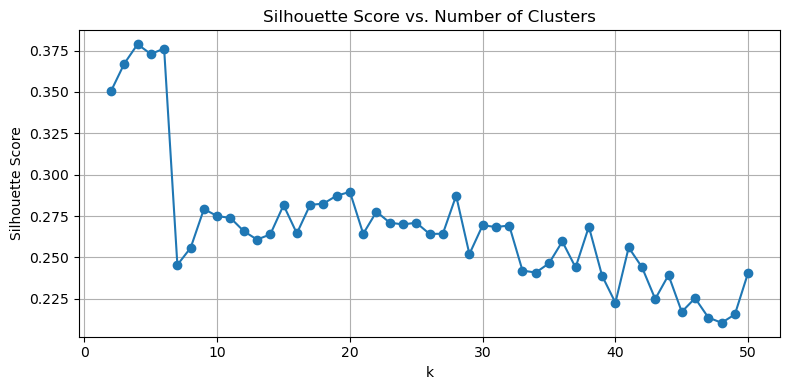

In [7]:
frog_mfcc_df = pd.read_csv(Path("../data/Frogs_MFCCs.csv"))
if 'RecordID' in frog_mfcc_df.columns:
    frog_mfcc_df = frog_mfcc_df.drop(columns='RecordID')

#numeric features and true labels
features = frog_mfcc_df.drop(columns=['Family','Genus','Species']).values
labels   = frog_mfcc_df[['Family','Genus','Species']]

#silhouette-based k selection
def find_optimal_k(X, k_min=2, k_max=50, n_init=5, sample_size=5000):
    ks = list(range(k_min, k_max+1))
    sil_scores = []
    N = X.shape[0]
    sample = min(sample_size, N)
    
    for k in ks:
        km = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=n_init,
            random_state=42
        )
        lbls = km.fit_predict(X)
        score = silhouette_score(X, lbls, sample_size=sample, random_state=42)
        sil_scores.append(score)
    
    return ks, sil_scores

#silhouette scores
k_range, sil_scores = find_optimal_k(features)

#best k
best_k = k_range[int(np.argmax(sil_scores))]
print(f"Optimal number of clusters (k): {best_k}")

#top 5 scores
silhouette_df = pd.DataFrame({
    'Clusters': k_range,
    'Silhouette Score': sil_scores
})
print(silhouette_df.nlargest(5, 'Silhouette Score'))

#Plot
plt.figure(figsize=(8, 4))
plt.plot(silhouette_df['Clusters'], silhouette_df['Silhouette Score'], marker='o')
plt.title("Silhouette Score vs. Number of Clusters")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()

k = 4 is a good choice from above result

### 2.(b) In each cluster, determine which family is the majority by reading the true labels. Repeat for genus and species.

In [8]:
df = pd.read_csv(Path("../data/Frogs_MFCCs.csv"))
if 'RecordID' in df.columns:
    df = df.drop(columns='RecordID')

features_df = df.select_dtypes(include='number').reset_index(drop=True)

#multi‐label columns
true_labels_df = df.iloc[:, -3:].reset_index(drop=True)

best_k = 4

def analyze_kmeans_clusters(features_df: pd.DataFrame,
                            true_labels_df: pd.DataFrame,
                            num_clusters: int):
    km = KMeans(
        n_clusters=num_clusters,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    clusters = km.fit_predict(features_df)
    
    #cluster assignments with true labels
    combined_df = pd.concat([
        true_labels_df,
        pd.Series(clusters, name='Cluster')
    ], axis=1)
    
    #majority class per label in each cluster
    cluster_majorities = {}
    for cid in range(num_clusters):
        subset = combined_df[combined_df['Cluster'] == cid]
        majority = {
            label: subset[label].mode()[0]
            for label in true_labels_df.columns
        }
        cluster_majorities[cid] = majority
    
    return km, combined_df, cluster_majorities

kmeans_model, clustered_df, majority_map = analyze_kmeans_clusters(features_df, true_labels_df, best_k)
print(majority_map)

{0: {'Family': 'Leptodactylidae', 'Genus': 'Adenomera', 'Species': 'AdenomeraHylaedactylus'}, 1: {'Family': 'Hylidae', 'Genus': 'Hypsiboas', 'Species': 'HypsiboasCinerascens'}, 2: {'Family': 'Dendrobatidae', 'Genus': 'Ameerega', 'Species': 'Ameeregatrivittata'}, 3: {'Family': 'Hylidae', 'Genus': 'Hypsiboas', 'Species': 'HypsiboasCordobae'}}


Output:<br>
0: {'Family': 'Leptodactylidae', 'Genus': 'Adenomera', 'Species': 'AdenomeraHylaedactylus'}, <br>
1: {'Family': 'Hylidae', 'Genus': 'Hypsiboas', 'Species': 'HypsiboasCinerascens'}, <br>
2: {'Family': 'Dendrobatidae', 'Genus': 'Ameerega', 'Species': 'Ameeregatrivittata'}, <br>
3: {'Family': 'Hylidae', 'Genus': 'Hypsiboas', 'Species': 'HypsiboasCordobae'}<br>


### 2.(c) Now for each cluster you have a majority label triplet (family, genus, species). Calculate the average Hamming distance, Hamming score, and Hamming loss between the true labels and the labels assigned by clusters

In [9]:
df = pd.read_csv(Path("../data/Frogs_MFCCs.csv")).drop(columns=['RecordID'], errors='ignore')
X = df.select_dtypes(include=[np.number]).values
label_cols = ['Family', 'Genus', 'Species']
labels_df = df[label_cols].reset_index(drop=True)
true_arr = labels_df.values

#optimal k once
def optimal_k_by_silhouette(X, k_min=2, k_max=50, n_init=5, sample_size=2000):
    best_k, best_score = None, -1.0
    N = X.shape[0]
    sample = min(N, sample_size)
    for k in range(k_min, k_max + 1):
        km = KMeans(n_clusters=k, n_init=n_init, random_state=42)
        lbls = km.fit_predict(X)
        score = silhouette_score(X, lbls, sample_size=sample, random_state=42)
        if score > best_score:
            best_k, best_score = k, score
    return best_k

optimal_k_val = optimal_k_by_silhouette(X)
print(f"Optimal k = {optimal_k_val}")

#Monte Carlo to compute Hamming metrics
n_runs = 50
hamming_distances = []

for seed in range(n_runs):
    # cluster assignment
    clusters = KMeans(
        n_clusters=optimal_k_val,
        init='random',
        n_init=1,
        random_state=seed
    ).fit_predict(X)
    
    # attach cluster labels
    labels_df['Cluster'] = clusters
    
    # majority vote per cluster
    mode_df = (
        labels_df
        .groupby('Cluster')[label_cols]
        .agg(lambda col: col.mode().iloc[0])
    )
    
    #abels for each sample
    pred_arr = mode_df.values[clusters]
    mismatches_per_sample = (true_arr != pred_arr).sum(axis=1)
    hamming_distances.append(mismatches_per_sample.mean())

#Aggregate metrics
avg_distance = np.mean(hamming_distances)        # avg # labels wrong per sample
avg_loss     = avg_distance / len(label_cols)    # normalized by 3 labels
avg_score    = 1 - avg_loss

print(f"Average Hamming Distance: {avg_distance:.3f}")
print(f"Average Hamming Score:    {avg_score:.3f}")
print(f"Average Hamming Loss:     {avg_loss:.3f}")

Optimal k = 6
Average Hamming Distance: 0.628
Average Hamming Score:    0.791
Average Hamming Loss:     0.209


In [10]:
df = pd.read_csv(Path("../data/Frogs_MFCCs.csv")).drop(columns=['RecordID'], errors='ignore')
X = df.select_dtypes(include=[np.number]).values
labels_df = df[['Family','Genus','Species']].reset_index(drop=True)
true_arr = labels_df.values


optimal_k_val = 6

# 3) Monte Carlo for all three
n_runs = 50
dists, losses, scores = [], [], []

for seed in range(n_runs):
    clusters = KMeans(
        n_clusters=optimal_k_val,
        init='random',
        n_init=1,
        random_state=seed
    ).fit_predict(X)
    
    labels_df['Cluster'] = clusters
    mode_df = (
        labels_df
        .groupby('Cluster')[['Family','Genus','Species']]
        .agg(lambda col: col.mode().iloc[0])
    )
    pred_arr = mode_df.values[clusters]
    
    mismatch = (true_arr != pred_arr)
    d = mismatch.sum(axis=1).mean()              # avg mismatches per sample
    l = mismatch.sum() / mismatch.size           # fraction wrong
    s = 1 - l                                    
    
    dists.append(d)
    losses.append(l)
    scores.append(s)

print(f"Avg Hamming distance: {np.mean(dists):.4f}")
print(f"Avg Hamming loss:     {np.mean(losses):.4f}")
print(f"Avg Hamming score:    {np.mean(scores):.4f}")


Avg Hamming distance: 0.6279
Avg Hamming loss:     0.2093
Avg Hamming score:    0.7907


Output:

### 3] ISLR 12.6.2

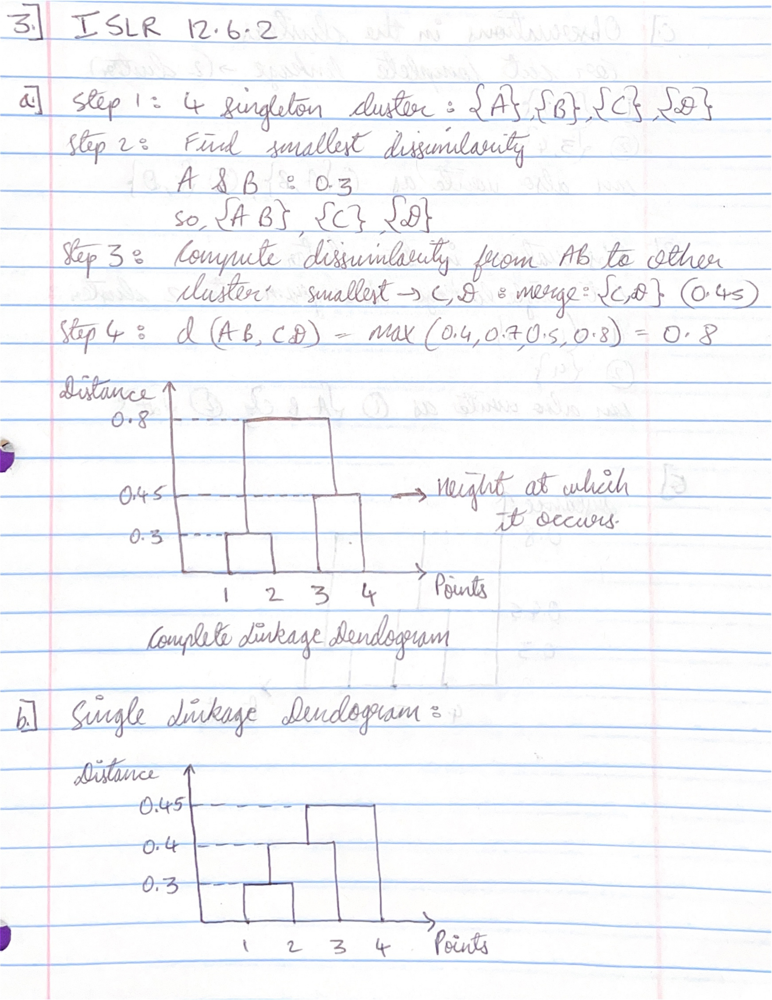
<br>
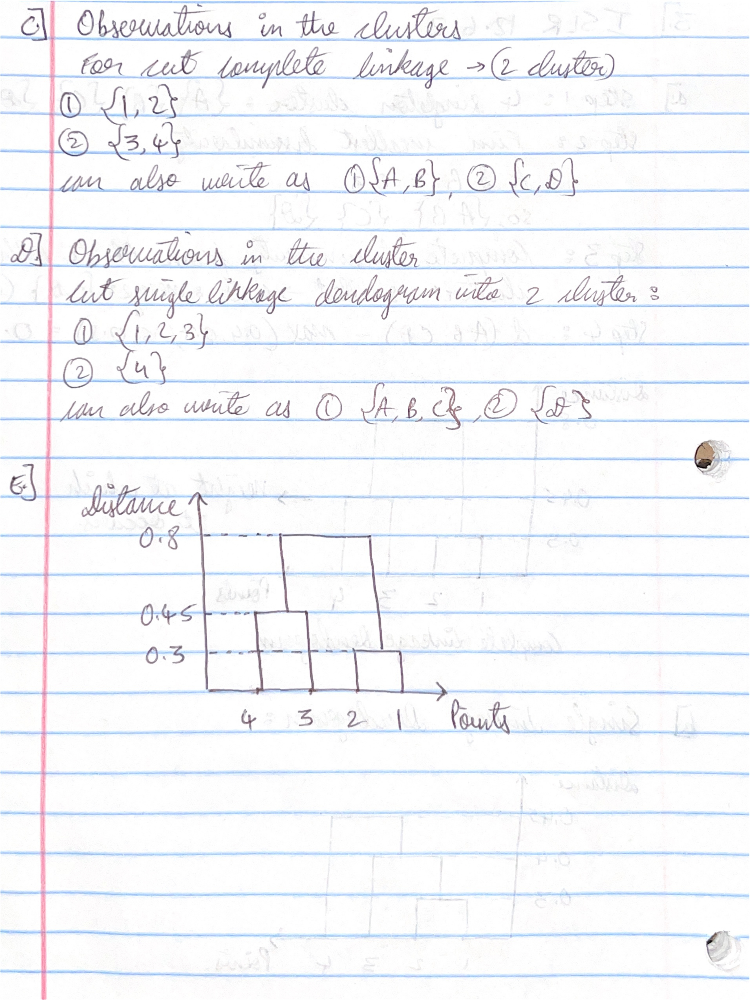

### References

https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html <br>

https://datagy.io/python-support-vector-machines/<br>

https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html<br>

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html<br>

https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html#sklearn.svm.LinearSVC<br>
